# Arbitrary Discretisation with `ArbitraryDiscretiser`

Discretisation converts a continuous numerical variable into intervals, called **bins**. The `feature-engine` `ArbitraryDiscretiser` lets a domain expert choose the boundaries instead of deriving them from the data distribution.

In this tutorial we use the Ames Housing dataset and the variables:

- `area`: land area in square feet.
- `bedrooms`: above-ground living area in square feet.
- `price`: sale price, used only for analysis and visualisation.

The notebook covers:
1. loading and inspecting the data;
2. separating training and test sets;
3. choosing domain-informed boundaries;
4. integer bin output;
5. labelled interval output;
6. string/object output;
7. unseen and extreme values; and
8. advantages, limitations, and model usage.

## 1. Imports and data location

Keeping the data split before choosing bins prevents test-set information from influencing the transformation. The cell searches for `housing.csv` beside this notebook, in the encoding folder, and in a few nearby locations.

In [3]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Install Feature-engine in the active notebook kernel if it is unavailable.
try:
    from feature_engine.discretisation import ArbitraryDiscretiser
except ModuleNotFoundError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "feature-engine"])
    from feature_engine.discretisation import ArbitraryDiscretiser

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
np.random.seed(42)


# Resolve project data paths relative to the current notebook working directory.
cwd = Path.cwd().resolve()
search_roots = [cwd, *cwd.parents]
relative_candidates = [
    Path("housing.csv"),
    Path("../encoding/housing.csv"),
    Path("feature-engineering/encoding/housing.csv"),
    Path("encoding/housing.csv"),
]
csv_path = None
for root in search_roots:
    for candidate in relative_candidates:
        candidate_path = (root / candidate).resolve()
        if candidate_path.exists():
            csv_path = candidate_path
            break
    if csv_path is not None:
        break

if csv_path is None:
    raise FileNotFoundError("housing.csv was not found through relative project paths.")

csv_relative_path = Path(os.path.relpath(csv_path, cwd))
data = pd.read_csv(csv_path)
print("Dataset:", csv_relative_path)
print("Shape:", data.shape)
data.head()

  Using cached feature_engine-1.9.4-py3-none-any.whl.metadata (10 kB)
Using cached feature_engine-1.9.4-py3-none-any.whl (243 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 10.6 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [feature-engine]m [feature-engine]
Dataset: ../encoding/housing.csv
Shape: (545, 3)


,area,bedrooms,price
0,7420,4,13300000
1,8960,4,12250000
2,9960,3,12250000
3,7500,4,12215000
4,7420,4,11410000


## 2. Inspect the dataset

We confirm variable types, missing values, and the distribution of the two variables that we will discretise. In Ames housing data, these variables are continuous numeric measurements rather than categorical codes.

Selected variable types:


,dtype
area,int64
bedrooms,int64
price,int64


Missing values:


,missing_count
area,0
bedrooms,0
price,0


,area,bedrooms,price
count,545.0,545.0,545.0
mean,5150.5,3.0,4766729.2
std,2170.1,0.7,1870439.6
min,1650.0,1.0,1750000.0
25%,3600.0,2.0,3430000.0
50%,4600.0,3.0,4340000.0
75%,6360.0,3.0,5740000.0
max,16200.0,6.0,13300000.0


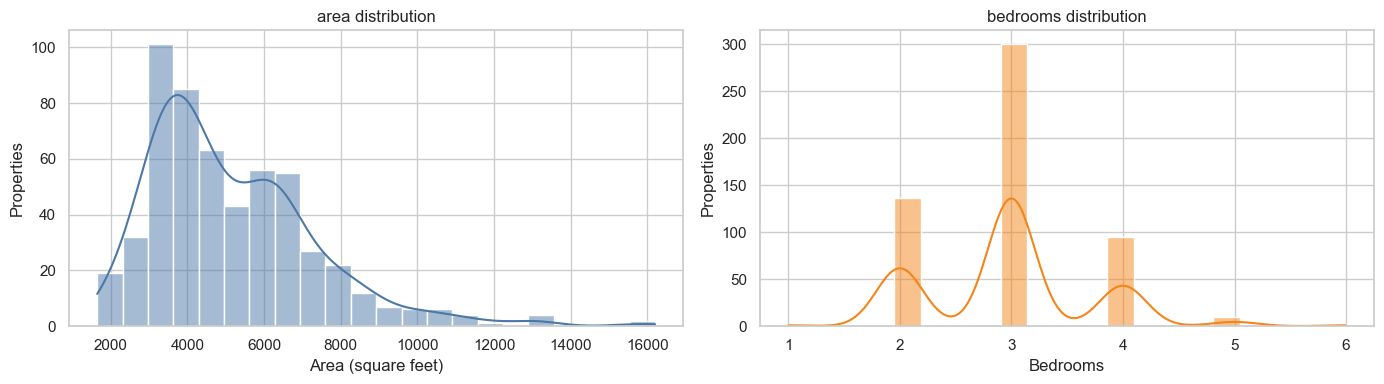

In [4]:
print("Selected variable types:")
display(data[["area", "bedrooms", "price"]].dtypes.to_frame("dtype"))

print("Missing values:")
display(data[["area", "bedrooms", "price"]].isna().sum().to_frame("missing_count"))

display(data[["area", "bedrooms", "price"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data["area"], kde=True, ax=axes[0], color="#4C78A8")
axes[0].set(title="area distribution", xlabel="Area (square feet)", ylabel="Properties")
sns.histplot(data["bedrooms"], kde=True, ax=axes[1], color="#F58518")
axes[1].set(title="bedrooms distribution", xlabel="Bedrooms", ylabel="Properties")
plt.tight_layout()
plt.show()

### Interpretation

The distributions are right-skewed and contain outliers. Arbitrary discretisation can make domain-sized ranges easier to interpret, but domain boundaries should be chosen for the problem rather than to optimise patterns in the test data.

## 3. Training/test split

We remove the identifier `Id` and the target `price` from the predictor matrix. A reproducible 30% test split mirrors the reference lesson.

In [5]:
X = data.drop(columns=["price"])
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Boundary selection used for examples below: training values only for range checks")
print("Training area range:", (X_train["area"].min(), X_train["area"].max()))
print("Training bedrooms range:", (X_train["bedrooms"].min(), X_train["bedrooms"].max()))

X_train: (381, 2)
X_test: (164, 2)
Boundary selection used for examples below: training values only for range checks
Training area range: (np.int64(1836), np.int64(15600))
Training bedrooms range: (np.int64(1), np.int64(5))


## 4. What the discretiser needs

Supply a dictionary in which each key is a numerical column and each value is an ordered list of bin limits:

```python
{
    "area": [-np.inf, 4000, 8000, 12000, 16000, 20000, np.inf],
    "bedrooms": [-np.inf, 1, 2, 3, 4, np.inf]
}
```

With six limits, `np.inf` included, the transformed output has **five intervals** because Feature-engine uses the boundaries as interval edges. The intervals in the reference example are:

- area: below 4,000; 4,000–8,000; 8,000–12,000; 12,000–16,000; 16,000–20,000; and 20,000 and above.
- bedrooms: below 500; 500–1,000; 1,000–1,500; 1,500–2,000; 2,000–2,500; and 2,500 and above.

`-np.inf` and `np.inf` ensure that values outside the chosen finite boundaries are still assigned a bin.

In [6]:
binning_dict = {
    "area": [-np.inf, 4000, 8000, 12000, 16000, 20000, np.inf],
    "bedrooms": [-np.inf, 1, 2, 3, 4, np.inf],
}

# A boundary strictly inside the data range should be used only as a domain example;
# values outside the first and last finite boundaries are covered by infinities.
print({col: len(edges) - 1 for col, edges in binning_dict.items()})

{'area': 6, 'bedrooms': 5}


## 5. Integer bin output

With `return_object=False` and `return_boundaries=False`, each interval is represented by a numeric integer. Because the default is for these options to be false, the transformation preserves a numeric data type while discarding the original continuous measurement.

In [8]:
discretiser = ArbitraryDiscretiser(
    binning_dict=binning_dict,
    return_boundaries=False,
    return_object=False,
)
discretiser.fit(X_train)

train_t = discretiser.transform(X_train)
test_t = discretiser.transform(X_test)

comparison = pd.concat([
    X_train[["area", "bedrooms"]].reset_index(drop=False),
    train_t[["area", "bedrooms"]].add_suffix("_bin").reset_index(drop=True),
], axis=1)
comparison.columns = ["original_index", "area", "bedrooms", "area_bin", "bedrooms_bin"]
display(comparison.head(12))
print("Binned dtypes:")
print(train_t[["area", "bedrooms"]].dtypes)

,original_index,area,bedrooms,area_bin,bedrooms_bin
0,454,4500,3,1,2
1,392,3990,3,0,2
2,231,4320,3,1,2
3,271,1905,5,0,4
4,250,3510,3,0,2
5,541,2400,3,0,2
6,461,4960,2,1,1
7,124,6525,3,1,2
8,154,3650,3,0,2
9,451,6750,2,1,1


Binned dtypes:
area        int64
bedrooms    int64
dtype: object


### Manual check

The integer assigned to each interval can be verified against `pandas.cut`. This is also useful when explaining the convention to students. Feature-engine assigns intervals in ascending order beginning with zero.

In [9]:
manual_lot = pd.cut(
    X_train["area"].iloc[:10],
    bins=binning_dict["area"],
    labels=False,
    include_lowest=True,
)
manual_area = pd.DataFrame({
    "area": X_train["area"].iloc[:10].values,
    "manual_area_bin": manual_lot.to_numpy(),
    "FeatureEngine_area_bin": train_t["area"].iloc[:10].to_numpy(),
})
display(manual_area)

,area,manual_area_bin,FeatureEngine_area_bin
0,4500,1,1
1,3990,0,0
2,4320,1,1
3,1905,0,0
4,3510,0,0
5,2400,0,0
6,4960,1,1
7,6525,1,1
8,3650,0,0
9,6750,1,1


## 6. Interval labels

Setting `return_boundaries=True` preserves readable interval boundaries in the output. These values are strings or objects by design and are suitable for reporting, but they should usually be expanded through one-hot encoding before fitting an estimator.

In [10]:
labelled_discretiser = ArbitraryDiscretiser(
    binning_dict=binning_dict,
    return_boundaries=True,
    return_object=True,
)
labelled_discretiser.fit(X_train)
train_labelled = labelled_discretiser.transform(X_train)
test_labelled = labelled_discretiser.transform(X_test)

display(pd.concat([
    X_train[["area", "bedrooms"]].head(10).reset_index(drop=True),
    train_labelled[["area", "bedrooms"]].head(10).add_prefix("bin_").reset_index(drop=True),
], axis=1))
print("Output types:", train_labelled[["area", "bedrooms"]].dtypes.to_dict())

,area,bedrooms,bin_area,bin_bedrooms
0,4500,3,"(4000.0, 8000.0]","(2.0, 3.0]"
1,3990,3,"(-inf, 4000.0]","(2.0, 3.0]"
2,4320,3,"(4000.0, 8000.0]","(2.0, 3.0]"
3,1905,5,"(-inf, 4000.0]","(4.0, inf]"
4,3510,3,"(-inf, 4000.0]","(2.0, 3.0]"
5,2400,3,"(-inf, 4000.0]","(2.0, 3.0]"
6,4960,2,"(4000.0, 8000.0]","(1.0, 2.0]"
7,6525,3,"(4000.0, 8000.0]","(2.0, 3.0]"
8,3650,3,"(-inf, 4000.0]","(2.0, 3.0]"
9,6750,2,"(4000.0, 8000.0]","(1.0, 2.0]"


Output types: {'area': dtype('O'), 'bedrooms': dtype('O')}


## 7. Visualise original and discretised distributions

Integer bins retain the ordering of intervals. With ordered labels, charts and tables can show whether a domain-sized interpretation changes with the numeric category.

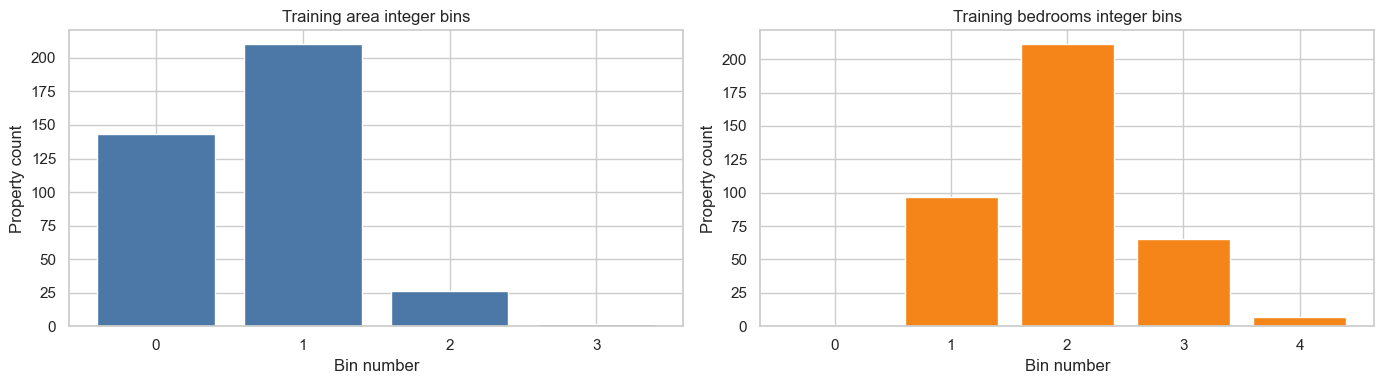

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

lot_counts = train_t["area"].value_counts().sort_index()
axes[0].bar(lot_counts.index.astype(str), lot_counts.values, color="#4C78A8")
axes[0].set(title="Training area integer bins", xlabel="Bin number", ylabel="Property count")

living_counts = train_t["bedrooms"].value_counts().sort_index()
axes[1].bar(living_counts.index.astype(str), living_counts.values, color="#F58518")
axes[1].set(title="Training bedrooms integer bins", xlabel="Bin number", ylabel="Property count")

plt.tight_layout()
plt.show()

,count,median,mean
area_bin,,,
0,143,3430000.0,3607203.0
1,210,5180000.0,5433864.0
2,26,5180000.0,5653038.0
3,2,6366500.0,6366500.0


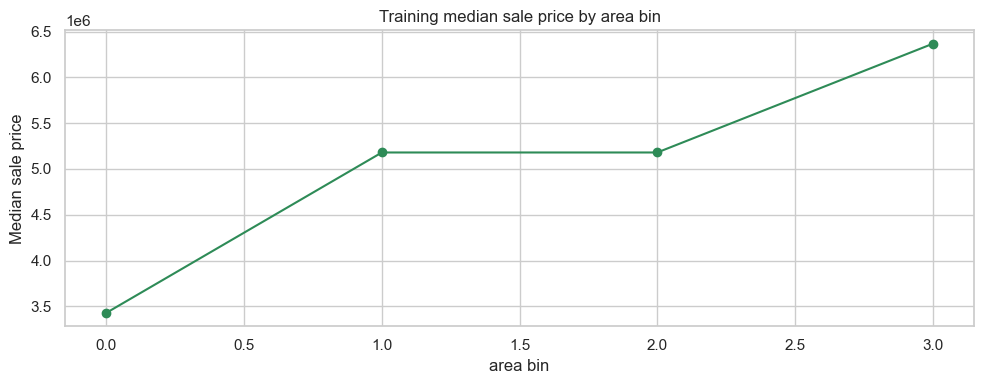

In [12]:
# Calculate the mean sale price for each interval in the training data.
plot_df = pd.DataFrame({
    "area_bin": train_t["area"].to_numpy(),
    "bedrooms_bin": train_t["bedrooms"].to_numpy(),
    "price": y_train.to_numpy(),
})

summary = plot_df.groupby("area_bin")["price"].agg(["count", "median", "mean"])
display(summary.round(0))

ax = summary["median"].plot(marker="o", figsize=(10, 4), color="#2E8B57")
ax.set_title("Training median sale price by area bin")
ax.set_xlabel("area bin")
ax.set_ylabel("Median sale price")
plt.tight_layout()
plt.show()

### Written interpretation

The counts reveal which domain ranges contain many observations. The relationship between the median price and bin number is not guaranteed to be monotonic: arbitrary boundaries can create weakly ordered or non-monotonic category effects. Models should be evaluated because bins are not mathematically guaranteed to improve predictive performance.

## 8. Handle values at or beyond the boundaries

The infinities are not literal numeric row values. They define the open-ended first and last intervals, so newly observed extreme values remain in a bin rather than producing an error.

In [13]:
# Align the demonstration frames so both columns have the same index length.
edge_examples = pd.DataFrame({
    "area": [-500, 3999, 4000, 7999, 8000, 15999, 16000, 25000],
    "bedrooms": [-1, 1, 2, 2, 3, 3, 4, 10],
})
display(edge_examples)
display(discretiser.transform(edge_examples))

,area,bedrooms
0,-500,-1
1,3999,1
2,4000,2
3,7999,2
4,8000,3
5,15999,3
6,16000,4
7,25000,10


,area,bedrooms
0,0,0
1,0,0
2,0,1
3,1,1
4,1,2
5,3,2
6,3,3
7,5,4


## 9. Numeric or categorical use in a model

An integer bin is ordered numeric data: learners may interpret bin `3` as larger than bin `1`, but the distances between bins remain arbitrary. If the category should have no numerical distance, pass it to a one-hot encoder. The example pipeline below compares:

- raw continuous `area` and `bedrooms`;
- ordered integer bins;
- one-hot encoded bins.

The remaining Ames predictors are not included in this small demonstration so that the comparison isolates discretisation.

,representation,MAE,R2
0,Continuous,1.106604e+06,0.3812
2,One-hot bins,1.140129e+06,0.3632
1,Ordered integer bins,1.145559e+06,0.3777


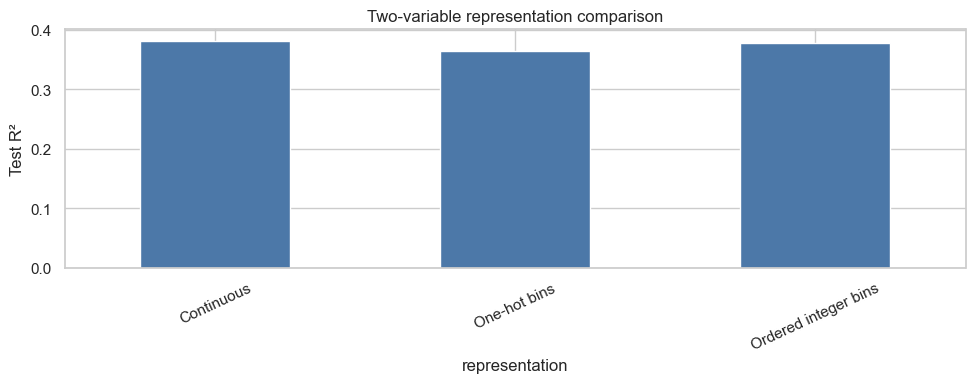

In [14]:
# Continuous linear model
def fit_linear(X_fit, X_holdout):
    model = LinearRegression()
    model.fit(X_fit[["area", "bedrooms"]], y_train)
    prediction = model.predict(X_holdout[["area", "bedrooms"]])
    return prediction

continuous_pred = fit_linear(X_train, X_test)

# Ordered integer bins
auto_bin_model = LinearRegression()
auto_bin_model.fit(train_t[["area", "bedrooms"]], y_train)
integer_pred = auto_bin_model.predict(test_t[["area", "bedrooms"]])

# Binned as nominal categories via one-hot encoding
nominal_train = train_labelled[["area", "bedrooms"]]
nominal_test = test_labelled[["area", "bedrooms"]]
nominal_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
nominal_train_t = nominal_encoder.fit_transform(nominal_train)
nominal_test_t = nominal_encoder.transform(nominal_test)
nominal_model = LinearRegression()
nominal_model.fit(nominal_train_t, y_train)
nominal_pred = nominal_model.predict(nominal_test_t)

results = pd.DataFrame({
    "representation": ["Continuous", "Ordered integer bins", "One-hot bins"],
    "MAE": [
        mean_absolute_error(y_test, continuous_pred),
        mean_absolute_error(y_test, integer_pred),
        mean_absolute_error(y_test, nominal_pred),
    ],
    "R2": [
        r2_score(y_test, continuous_pred),
        r2_score(y_test, integer_pred),
        r2_score(y_test, nominal_pred),
    ],
}).sort_values("MAE")
display(results.round(4))

ax = results.set_index("representation")[["R2"]].plot.bar(figsize=(10, 4), rot=25, legend=False, color="#4C78A8")
ax.set_ylabel("Test R²")
ax.set_title("Two-variable representation comparison")
plt.tight_layout()
plt.show()

### Model interpretation

Discretisation is a representation choice, not automatically a performance improvement. One-hot bins can learn independent effects for each interval, while integer bins impose an ordered numeric interpretation and continuous values preserve distance information.

Use cross-validation to compare choices. For a production pipeline, the discretiser, one-hot encoder, imputer, and estimator should all be fitted inside training folds, rather than preparing the complete dataset first.

## 10. Optional Feature-engine notes and exercises

### `ArbitraryDiscretiser` options

- `binning_dict`: column-to-boundary mapping required by this tutorial.
- `return_boundaries=False`: return an integer bin ID.
- `return_boundaries=True`: return the interval boundaries.
- `return_object=False`: return numeric integer output.
- `return_object=True`: force object/string interval labels.
- Missing values remain missing unless imputed separately.
- Boundaries must be unique and ordered.
- Infinite limits are useful to define unbounded edge intervals.

### Exercises

1. Change the area boundary from 4,000 to 5,000. How many bins and observations change?
2. Create shorter and wider bedrooms intervals. Compare training distributions.
3. Add one-hot encoding and evaluate the intervals with a held-out test set.
4. Explore whether treating bins as ordered integers makes sense for your chosen business problem.
5. Move the discretiser into a scikit-learn pipeline with an imputer and estimator.

### Key conclusion

Arbitrary discretisation is most valuable when a domain expert has meaningful threshold values. It is not appropriate merely because it produces rounder-looking groups: boundaries should be justified, tested, and reviewed for drift as values change over time.